# Analyse de la campagne de mesures

Lit les résultats de `scripts/run_campaign.py` (dossier `data/campaign/<run>/`) et produit les tableaux p50/p95, le WER selon le bruit,
la précision du VAD, la latence en temps réel et le taux d'interruptions correctement gérées. Les définitions sont dans `docs/METRICS.md`.

**Relancer** : `RUN` ci-dessous (variable d'environnement `CAMPAIGN_RUN` ou le dernier dossier). Toutes les figures sont enregistrées dans `<run>/figs/`.

In [1]:
import json, os, sys
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))
from src.metrics.analysis import barge_verdict, percentiles, read_jsonl

runs = sorted((p for p in (ROOT / "data" / "campaign").glob("*/meta.json") if (p.parent / "latency.jsonl").exists()), key=lambda p: p.stat().st_mtime)   # campagnes complètes (l'écho est dans ECHO_RUN)
RUN = Path(os.environ["CAMPAIGN_RUN"]) if "CAMPAIGN_RUN" in os.environ else runs[-1].parent
FIGS = RUN / "figs"; FIGS.mkdir(exist_ok=True)
meta = json.loads((RUN / "meta.json").read_text())
cfg = meta["config"]
import yaml
cfg_base_end = yaml.safe_load((ROOT / "configs" / "base.yaml").read_text())["vad"]["end_silence_ms"]   # réglage actuel du serveur
WARMUP = cfg["latency"]["warmup_turns"]          # tours de chauffe exclus des statistiques de latence
TH = cfg["barge"]["thresholds"]

# Palette catégorielle (5 premiers emplacements de la palette validée : bleu, orange, aqua, jaune, magenta) ; texte en encres neutres
BLUE, ORANGE, AQUA, YELLOW, MAGENTA = "#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4"
INK, INK2, GRID, SURFACE = "#0b0b0b", "#52514e", "#e6e5e1", "#fcfcfb"
plt.rcParams.update({"figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "text.color": INK, "axes.labelcolor": INK2, "xtick.color": INK2, "ytick.color": INK2, "axes.edgecolor": GRID,
    "axes.spines.top": False, "axes.spines.right": False, "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.8,
    "axes.axisbelow": True, "font.size": 10.5, "axes.titlesize": 12, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "legend.frameon": False, "lines.linewidth": 2})

stt = pd.DataFrame(read_jsonl(RUN / "stt.jsonl"))
vad = pd.DataFrame(read_jsonl(RUN / "vad.jsonl"))
vad_n = pd.DataFrame(read_jsonl(RUN / "vad_noise.jsonl"))
lat = pd.DataFrame(read_jsonl(RUN / "latency.jsonl"))
bar = pd.DataFrame(read_jsonl(RUN / "barge.jsonl"))
fp = pd.DataFrame(read_jsonl(RUN / "barge_fp.jsonl"))
sweep = pd.DataFrame(read_jsonl(RUN / "vad_sweep.jsonl"))
bsweep = pd.DataFrame(read_jsonl(RUN / "barge_sweep.jsonl"))
print(f"Campagne {RUN.name} — {'rapide' if meta['quick'] else 'complète'} — {meta['duration_s']} s — coût ≈ {meta['cost_usd_delta']} $")
print({k: len(v) for k, v in dict(stt=stt, vad=vad, vad_bruit=vad_n, latence=lat, barge=bar, faux_positifs=fp).items()})

Campagne run1 — complète — 2084 s — coût ≈ 1.3893 $
{'stt': 170, 'vad': 90, 'vad_bruit': 8, 'latence': 50, 'barge': 24, 'faux_positifs': 4}


## 1. Transcription (Whisper de l'école) : WER selon le bruit

SNR = rapport parole/bruit mesuré sur les segments de parole. Bruit blanc, et « foule » = 4 voix synthétiques qui parlent en même temps.
Le WER est calculé après normalisation identique pour toutes les conditions (minuscules, ponctuation retirée).

bruit,babble,white
snr,,
propre,0.4%,0.4%
20,0.4%,0.4%
10,0.4%,0.4%
5,3.8%,1.9%
0,66.6%,16.1%


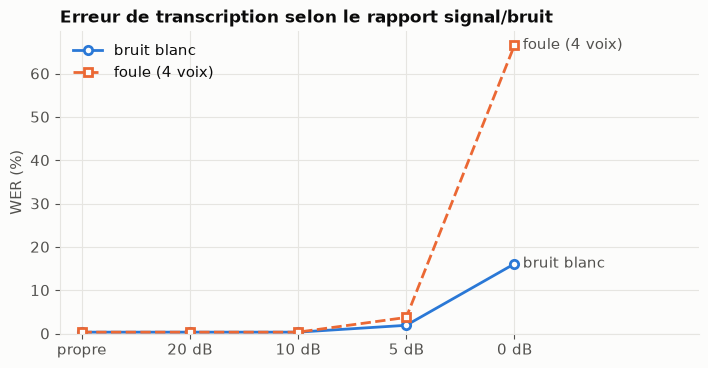

,STT p50 (ms),STT p95 (ms),n
noise,,,
babble 0.0 dB,476.0,674.0,20.0
babble 10.0 dB,442.0,2486.0,20.0
babble 20.0 dB,450.0,1416.0,20.0
babble 5.0 dB,423.0,875.0,20.0
none,453.0,710.0,10.0
white 0.0 dB,479.0,928.0,20.0
white 10.0 dB,475.0,1046.0,20.0
white 20.0 dB,462.0,581.0,20.0
white 5.0 dB,451.0,651.0,20.0


In [2]:
ok = stt[stt.wer.notna()].copy()
snrs = sorted(cfg["noise"]["snrs_db"], reverse=True)
order = ["propre"] + [str(s) for s in snrs]
clean = ok[ok.noise == "none"].wer
rows = []
for noise in cfg["noise"]["types"]:
    rows.append((noise, "propre", clean.mean(), len(clean)))
    for s in snrs:
        d = ok[(ok.noise == noise) & (ok.snr == s)].wer
        rows.append((noise, str(s), d.mean() if len(d) else np.nan, len(d)))
w = pd.DataFrame(rows, columns=["bruit", "snr", "wer", "n"])
display(w.pivot(index="snr", columns="bruit", values="wer").reindex(order).style.format("{:.1%}").set_caption("WER moyen"))

fig, ax = plt.subplots(figsize=(7.2, 3.8))
styles = {"white": (BLUE, "-", "o", "bruit blanc"), "babble": (ORANGE, "--", "s", "foule (4 voix)")}
for noise, (col, ls, mk, label) in styles.items():
    d = w[w.bruit == noise].set_index("snr").reindex(order)
    ax.plot(range(len(order)), d.wer * 100, color=col, ls=ls, marker=mk, ms=6, mfc=SURFACE, mew=2, label=label)
    ax.annotate(label, (len(order) - 1, d.wer.iloc[-1] * 100), xytext=(6, 0), textcoords="offset points", va="center", color=INK2)
ax.set_xticks(range(len(order)), [o if o == "propre" else f"{o} dB" for o in order])
ax.set_ylabel("WER (%)"); ax.set_title("Erreur de transcription selon le rapport signal/bruit")
ax.set_xlim(-0.2, len(order) - 0.2 + 0.9); ax.set_ylim(bottom=0); ax.legend(loc="upper left")
fig.tight_layout(); fig.savefig(FIGS / "wer_vs_snr.png", dpi=150); plt.show()

lat_stt = ok.groupby(ok.noise.where(ok.noise == "none", ok.noise + " " + ok.snr.astype(str) + " dB")).stt_ms.apply(lambda s: pd.Series(percentiles(s))).unstack()
display(lat_stt.round(0).rename(columns={"p50": "STT p50 (ms)", "p95": "STT p95 (ms)"}))
errs = stt[stt.wer.isna()]
if len(errs): display(Markdown(f"**{len(errs)} appels STT en erreur** (exclus) : {errs.error.value_counts().to_dict()}"))

## 2. Détection de la parole (VAD Silero + fin de tour)

Mesures hors ligne sur les mêmes stimuli. *Début* : erreur de l'instant de début estimé (0 = exact). *Délai de fin de tour* : instant où la fin est déclarée moins la fin réelle de parole (≈ 450 ms de silence exigé + 1 trame).
*Coupé* : l'énoncé est découpé en plusieurs segments (fin de tour déclarée au milieu d'une phrase). *Manqué* : aucune fin détectée.

,n,manqué %,coupé %,début p50 (ms),début p95 (ms),fin p50 (ms),fin p95 (ms)
condition,,,,,,,
propre,10.0,0.0,30.0,32.0,67.0,499.0,535.0
white 20 dB,10.0,0.0,20.0,32.0,219.0,543.0,637.0
white 10 dB,10.0,0.0,20.0,32.0,219.0,565.0,715.0
white 5 dB,10.0,0.0,20.0,64.0,262.0,594.0,710.0
white 0 dB,10.0,0.0,10.0,128.0,320.0,655.0,764.0
babble 20 dB,10.0,50.0,0.0,-544.0,-26.0,628.0,817.0
babble 10 dB,10.0,100.0,0.0,-672.0,-445.0,NaN,NaN
babble 5 dB,10.0,100.0,0.0,-624.0,-240.0,NaN,NaN
babble 0 dB,10.0,100.0,0.0,-736.0,-686.0,NaN,NaN


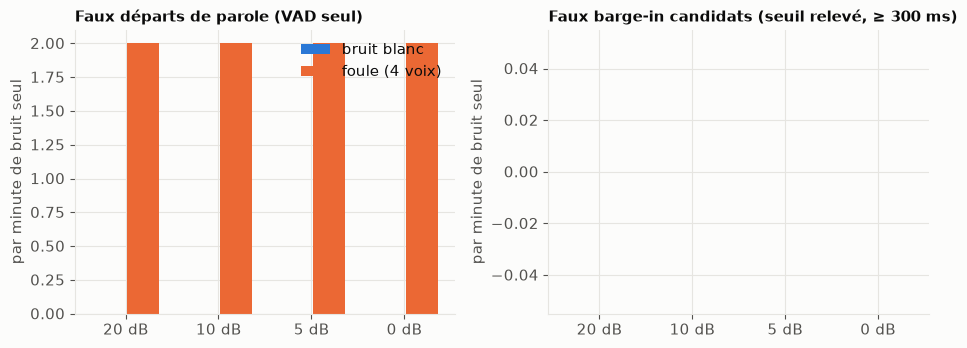

,noise,snr,minutes,false_starts,false_starts_per_min,false_barge_candidates,false_barge_per_min
0,white,20,1.0,0,0.0,0,0.0
1,white,10,1.0,0,0.0,0,0.0
2,white,5,1.0,0,0.0,0,0.0
3,white,0,1.0,0,0.0,0,0.0
4,babble,20,1.0,2,2.0,0,0.0
5,babble,10,1.0,2,2.0,0,0.0
6,babble,5,1.0,2,2.0,0,0.0
7,babble,0,1.0,2,2.0,0,0.0


In [3]:
v = vad.copy()
v["condition"] = np.where(v.noise == "none", "propre", v.noise + " " + v.snr.astype("Int64").astype(str) + " dB")
def agg(g):
    return pd.Series({"n": len(g), "manqué %": 100 * g.missed.mean(), "coupé %": 100 * g.cut.mean(),
        "début p50 (ms)": g.start_err_ms.median(), "début p95 (ms)": g.start_err_ms.quantile(.95),
        "fin p50 (ms)": g.endpoint_delay_ms.median(), "fin p95 (ms)": g.endpoint_delay_ms.quantile(.95)})
tab = v.groupby("condition").apply(agg, include_groups=False)
cond_order = ["propre"] + [f"{n} {s} dB" for n in cfg["noise"]["types"] for s in snrs]
display(tab.reindex([c for c in cond_order if c in tab.index]).round(0))

fig, axes = plt.subplots(1, 2, figsize=(9.5, 3.6))
d = vad_n.copy(); d["snr"] = d.snr.astype(int)
for ax, col, title in [(axes[0], "false_starts_per_min", "Faux départs de parole (VAD seul)"),
                       (axes[1], "false_barge_per_min", "Faux barge-in candidats (seuil relevé, ≥ 300 ms)")]:
    for i, (noise, (c, ls, mk, label)) in enumerate(styles.items()):
        s = d[d.noise == noise].sort_values("snr", ascending=False)
        ax.bar(np.arange(len(s)) + (i - .5) * 0.38, s[col], width=0.34, color=c, label=label)
    ax.set_xticks(range(len(snrs)), [f"{x} dB" for x in snrs]); ax.set_ylabel("par minute de bruit seul"); ax.set_title(title, fontsize=10.5)
axes[0].legend()
fig.tight_layout(); fig.savefig(FIGS / "vad_false_positives.png", dpi=150); plt.show()
display(vad_n.round(2))

### Compromis de la fin de tour (balayage hors ligne)

Même signaux, autre durée de silence exigée pour déclarer la fin de tour (`vad.end_silence_ms`). Une durée courte réduit la latence mais **coupe les phrases qui contiennent une pause** (l'agent répond au milieu de la phrase) ;
une durée longue l'évite mais ajoute ce délai à chaque réponse. Conditions : propre et bruit blanc (la foule est exclue : fin jamais détectée). Un « délai » négatif signifie que la première fin déclarée tombe avant la vraie fin de parole (coupure).

coupures          delai_p50        
groupe         bruit blanc propre bruit blanc  propre
end_silence_ms                                       
300                   0.50    0.5      -181.0  -593.0
450                   0.18    0.3       578.0   499.0
600                   0.10    0.1       714.0   652.0
800                   0.00    0.1       917.0   844.0
1000                  0.00    0.0      1141.0  1068.0

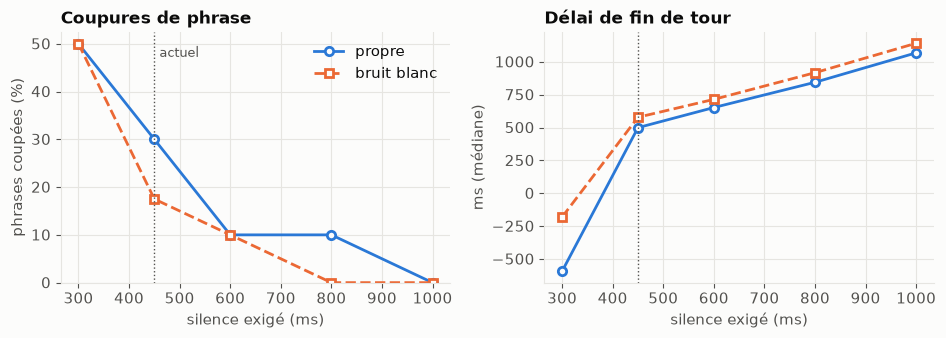

In [4]:
if len(sweep):
    sw = sweep[sweep.noise.isin(["none", "white"])].copy()
    sw["groupe"] = np.where(sw.noise == "none", "propre", "bruit blanc")
    agg = sw.groupby(["groupe", "end_silence_ms"]).agg(n=("cut", "size"), coupures=("cut", "mean"), delai_p50=("endpoint_delay_ms", "median")).reset_index()
    display(agg.pivot(index="end_silence_ms", columns="groupe", values=["coupures", "delai_p50"]).round(2))
    fig, axes = plt.subplots(1, 2, figsize=(9.6, 3.5))
    for g, c, ls, mk in [("propre", BLUE, "-", "o"), ("bruit blanc", ORANGE, "--", "s")]:
        d = agg[agg.groupe == g]
        axes[0].plot(d.end_silence_ms, d.coupures * 100, color=c, ls=ls, marker=mk, mfc=SURFACE, mew=2, ms=6, label=g)
        axes[1].plot(d.end_silence_ms, d.delai_p50, color=c, ls=ls, marker=mk, mfc=SURFACE, mew=2, ms=6, label=g)
    for ax, yl, t in [(axes[0], "phrases coupées (%)", "Coupures de phrase"), (axes[1], "ms (médiane)", "Délai de fin de tour")]:
        ax.set_xlabel("silence exigé (ms)"); ax.set_ylabel(yl); ax.set_title(t); ax.axvline(cfg_base_end, color=INK2, lw=1, ls=":")
    axes[0].set_ylim(bottom=0); axes[0].legend(); axes[0].text(cfg_base_end + 10, axes[0].get_ylim()[1] * .9, "actuel", color=INK2, fontsize=9)
    fig.tight_layout(); fig.savefig(FIGS / "endpoint_tradeoff.png", dpi=150); plt.show()

## 3. Latence en temps réel (serveur réel, micro simulé)

Chaque tour : l'énoncé est joué au micro simulé ; on mesure à l'arrivée des octets audio chez le client.
*Premier son* = fin de parole réelle → premier octet audio (accroche comprise). *Début de la réponse* = estimation serveur du moment où le contenu commence à être joué (après l'accroche si elle est plus longue que l'attente).
Les tours de chauffe (`warmup_turns`) sont exclus. Avec n petit, le p95 est indicatif.

,n,tours testés,échecs,ignorés,1er son (mesuré) p50,1er son (mesuré) p95,début réponse (est.) p50,début réponse (est.) p95,1er audio réponse (mesuré) p50,1er audio réponse (mesuré) p95,STT p50,STT p95,LLM TTFT p50,LLM TTFT p95,TTS 1er octet p50,TTS 1er octet p95,silence après accroche p50,silence après accroche p95
condition,,,,,,,,,,,,,,,,,,
clean_nofiller,9.0,10.0,0.0,0.0,2092.0,2478.0,2061.0,2453.0,2092.0,2478.0,756.0,1093.0,299.0,388.0,419.0,492.0,0.0,0.0
clean_filler,9.0,10.0,0.0,0.0,520.0,2280.0,2101.0,2485.0,2165.0,2550.0,817.0,963.0,307.0,470.0,476.0,566.0,393.0,548.0
white10_filler,9.0,10.0,0.0,0.0,582.0,2013.0,2246.0,2489.0,2342.0,2560.0,751.0,888.0,320.0,724.0,417.0,583.0,586.0,833.0
babble20_filler,1.0,4.0,3.0,6.0,2051.0,2051.0,1667.0,1667.0,2051.0,2051.0,567.0,567.0,226.0,226.0,378.0,378.0,0.0,0.0
babble10_filler,0.0,3.0,3.0,7.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


**Réponses prématurées** (l'agent commence à parler avant la fin de la phrase de l'utilisateur) et phrases découpées en plusieurs tours :

,tours,reponse_prematuree,phrase_en_plusieurs_tours
condition,,,
babble20_filler,1,0%,0%
clean_filler,10,20%,0%
clean_nofiller,10,0%,10%
white10_filler,10,10%,0%


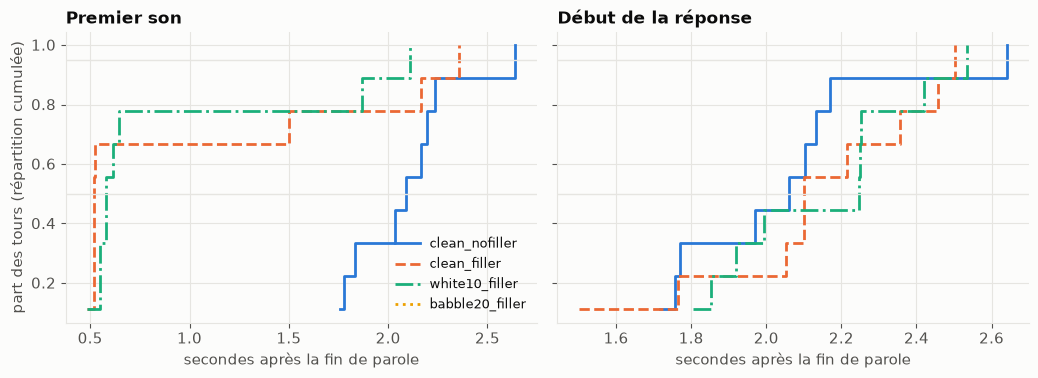

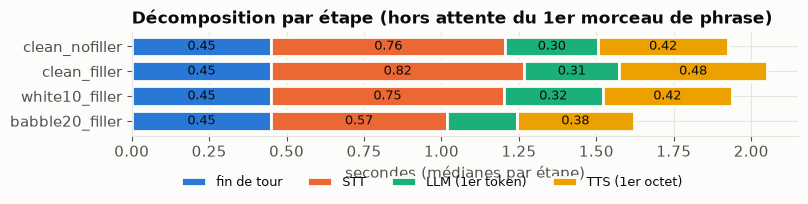

In [5]:
L = lat.copy()
if "skipped" not in L: L["skipped"] = False
L["skipped"] = L.skipped.fillna(False).astype(bool)
tested = L[~L.skipped]
fails = tested.groupby("condition").failed.sum()
n_tested = tested.groupby("condition").size()
skipped = L[L.skipped].groupby("condition").size()
L = L[(L.turn > WARMUP) & (~L.failed) & (~L.skipped)]
metrics = {"wall_first_ms": "1er son (mesuré)", "srv_content_ms": "début réponse (est.)", "wall_content_arrival_ms": "1er audio réponse (mesuré)",
           "stt_ms": "STT", "llm_ttft_ms": "LLM TTFT", "tts_ttfb_ms": "TTS 1er octet", "srv_gap_ms": "silence après accroche"}
rows = []
for cond, g in L.groupby("condition", sort=False):
    r = {"condition": cond, "n": len(g), "tours testés": int(n_tested.get(cond, 0)), "échecs": int(fails.get(cond, 0)), "ignorés": int(skipped.get(cond, 0))}
    for k, name in metrics.items():
        p = percentiles(g[k])
        r[f"{name} p50"], r[f"{name} p95"] = p["p50"], p["p95"]
    rows.append(r)
lt = pd.DataFrame(rows).set_index("condition")
for cond in fails.index:   # conditions où aucun tour n'a abouti n'ont pas de ligne de latence : on les signale quand même
    if cond not in lt.index:
        lt.loc[cond] = np.nan; lt.loc[cond, ["n", "tours testés", "échecs", "ignorés"]] = [0, int(n_tested.get(cond, 0)), int(fails[cond]), int(skipped.get(cond, 0))]
display(lt.round(0))

if "premature_start" in tested:
    pm = tested[~tested.failed].groupby("condition").agg(tours=("turn", "size"), reponse_prematuree=("premature_start", "mean"), phrase_en_plusieurs_tours=("n_user_turns", lambda s: (s > 1).mean()))
    display(Markdown("**Réponses prématurées** (l'agent commence à parler avant la fin de la phrase de l'utilisateur) et phrases découpées en plusieurs tours :"))
    display(pm.style.format({"reponse_prematuree": "{:.0%}", "phrase_en_plusieurs_tours": "{:.0%}"}))
order = [c["name"] for c in cfg["latency"]["conditions"] if c["name"] in L.condition.unique()]
all_conds = [c["name"] for c in cfg["latency"]["conditions"]]
colors = dict(zip(order, [BLUE, ORANGE, AQUA, YELLOW, MAGENTA]))
dashes = dict(zip(order, ["-", "--", "-.", ":", (0, (5, 1, 1, 1))]))
fig, axes = plt.subplots(1, 2, figsize=(10.5, 3.9), sharey=True)
for ax, col, title in [(axes[0], "wall_first_ms", "Premier son"), (axes[1], "srv_content_ms", "Début de la réponse")]:
    for cond in order:
        x = np.sort(L[L.condition == cond][col].dropna().values)
        if len(x) == 0: continue
        ax.step(x / 1000, np.arange(1, len(x) + 1) / len(x), where="post", color=colors[cond], ls=dashes[cond], label=cond)
    ax.axhline(.5, color=GRID, lw=1); ax.axhline(.95, color=GRID, lw=1)
    ax.set_xlabel("secondes après la fin de parole"); ax.set_title(title)
axes[0].set_ylabel("part des tours (répartition cumulée)"); axes[0].legend(loc="lower right", fontsize=9)
fig.tight_layout(); fig.savefig(FIGS / "latency_ecdf.png", dpi=150); plt.show()

stages = [("end_silence_ms", "fin de tour", BLUE), ("stt_ms", "STT", ORANGE), ("llm_ttft_ms", "LLM (1er token)", AQUA), ("tts_ttfb_ms", "TTS (1er octet)", YELLOW)]
med = L.groupby("condition")[[s for s, _, _ in stages]].median().reindex(order)
fig, ax = plt.subplots(figsize=(8.2, 2.9)); left = np.zeros(len(med))
for key, label, c in stages:
    vals = med[key].fillna(0).values / 1000
    ax.barh(range(len(med)), vals, left=left, color=c, edgecolor=SURFACE, linewidth=2, label=label)
    for i, (l_, v_) in enumerate(zip(left, vals)):
        if v_ > .25: ax.text(l_ + v_ / 2, i, f"{v_:.2f}", ha="center", va="center", color=INK, fontsize=9)
    left += vals
ax.set_yticks(range(len(med)), med.index); ax.invert_yaxis(); ax.set_xlabel("secondes (médianes par étape)")
ax.set_title("Décomposition par étape (hors attente du 1er morceau de phrase)"); ax.legend(ncol=4, loc="lower center", bbox_to_anchor=(.45, -.62), fontsize=9)
fig.tight_layout(); fig.savefig(FIGS / "latency_stages.png", dpi=150); plt.show()

## 4. Interruptions (barge-in)

Une interruption est **correctement gérée** si tous les critères sont vrais (`docs/METRICS.md`) : détectée dans le délai, lecture arrêtée sans audio résiduel, historique tronqué à un début de ce qui a été envoyé,
phrase interruptive comprise (WER ≤ seuil), et une réponse suivante est produite. Seuils dans `configs/campaign.yaml`.

**Interruptions correctement gérées : 14/21 = 67%** (3 essais invalides exclus : {'faux positif : interruption spontanée due au bruit': 3})

,réussies,essais,taux
condition,,,
babble 20 dB,2,3,67%
propre,8,12,67%
white 10 dB,4,6,67%


,réussies,essais,taux
offset_s,,,
1.000000,6,8,75%
3.000000,4,7,57%
5.000000,4,6,67%


,réussies,essais,taux
utt_id,,,
b_long,11,11,100%
b_short,3,10,30%


Phrases interruptives découpées en plusieurs tours (pause interne ≥ fin de tour) : **8/21**.

**Critères non satisfaits** (nombre d'essais) : {'detected': 6, 'stopped_clean': 0, 'truncated_ok': 1, 'understood': 7, 'answered': 1}

Délai de détection (début de parole → message d'interruption) : p50 **610 ms**, p95 **1540 ms** (n=21) ; seuil 800 ms.

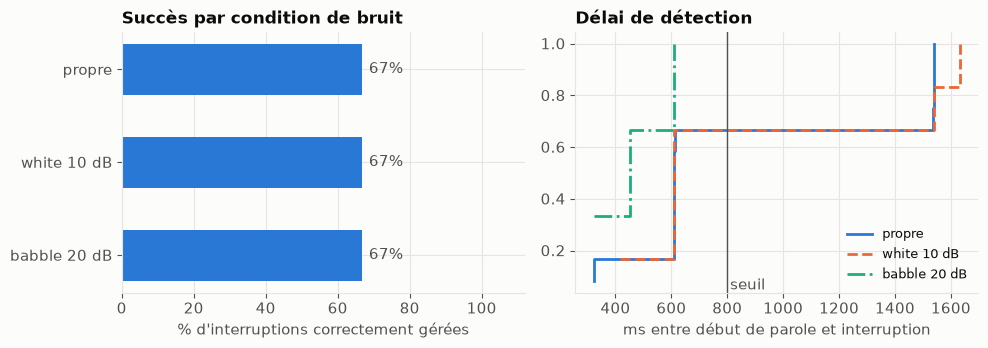

**Faux positifs** (l'agent parle, personne n'interrompt ; `invalid_reason` = l'agent n'a même pas pu répondre) :

,valid,false_interrupts,agent_audio_s
condition,,,
white 0 dB,True,0,17.1
babble 20 dB,True,1,0.0
babble 10 dB,True,1,0.0
babble 0 dB,True,1,0.0


In [6]:
B = bar.copy()
invalid = B[~B.valid] if len(B) else B
B = B[B.valid].copy() if len(B) else B
if len(B):
    V = pd.DataFrame([barge_verdict(r, TH["detect_max_ms"], TH["wer_max"]) for r in B.to_dict("records")], index=B.index)
    B = B.join(V)
    B["condition"] = np.where(B.noise == "none", "propre", B.noise + " " + B.snr.astype("Int64").astype(str) + " dB")
    n_ok, n = int(B.ok.sum()), len(B)
    display(Markdown(f"**Interruptions correctement gérées : {n_ok}/{n} = {n_ok / n:.0%}** ({len(invalid)} essais invalides exclus"
                     + (f" : {invalid.invalid_reason.value_counts().to_dict()}" if len(invalid) else "") + ")"))
    for by in ["condition", "offset_s", "utt_id"]:
        display(B.groupby(by).ok.agg(["sum", "count", "mean"]).rename(columns={"sum": "réussies", "count": "essais", "mean": "taux"}).style.format({"taux": "{:.0%}"}))
    if "n_user_turns" in B:
        display(Markdown(f"Phrases interruptives découpées en plusieurs tours (pause interne ≥ fin de tour) : **{int((B.n_user_turns > 1).sum())}/{len(B)}**."))
    crit = ["detected", "stopped_clean", "truncated_ok", "understood", "answered"]
    display(Markdown("**Critères non satisfaits** (nombre d'essais) : " + str({c: int((~B[c]).sum()) for c in crit})))
    d = B[B.detect_ms.notna()]
    p = percentiles(d.detect_ms); display(Markdown(f"Délai de détection (début de parole → message d'interruption) : p50 **{p['p50']:.0f} ms**, p95 **{p['p95']:.0f} ms** (n={p['n']}) ; seuil {TH['detect_max_ms']} ms."))

    fig, axes = plt.subplots(1, 2, figsize=(10, 3.6))
    g = B.groupby("condition").ok.mean().reindex([c for c in cond_order if c in B.condition.unique()])
    axes[0].barh(range(len(g)), g.values * 100, color=BLUE, height=.55)
    for i, v_ in enumerate(g.values): axes[0].text(v_ * 100 + 2, i, f"{v_:.0%}", va="center", color=INK2)
    axes[0].set_yticks(range(len(g)), g.index); axes[0].set_xlim(0, 112); axes[0].invert_yaxis()
    axes[0].set_xlabel("% d'interruptions correctement gérées"); axes[0].set_title("Succès par condition de bruit")
    for cond, c, ls in zip(B.condition.unique(), [BLUE, ORANGE, AQUA, YELLOW, MAGENTA], ["-", "--", "-.", ":", "-"]):
        x = np.sort(d[d.condition == cond].detect_ms.values)
        if len(x): axes[1].step(x, np.arange(1, len(x) + 1) / len(x), where="post", color=c, ls=ls, label=cond)
    axes[1].axvline(TH["detect_max_ms"], color=INK2, lw=1); axes[1].text(TH["detect_max_ms"] + 10, .05, "seuil", color=INK2)
    axes[1].set_xlabel("ms entre début de parole et interruption"); axes[1].set_title("Délai de détection"); axes[1].legend(fontsize=9)
    fig.tight_layout(); fig.savefig(FIGS / "barge_in.png", dpi=150); plt.show()
else:
    display(Markdown("_Aucun essai d'interruption._"))
if len(fp):
    f = fp.copy(); f["condition"] = f.noise + " " + f.snr.astype(int).astype(str) + " dB"
    display(Markdown("**Faux positifs** (l'agent parle, personne n'interrompt ; `invalid_reason` = l'agent n'a même pas pu répondre) :"))
    display(f[[c for c in ["condition", "valid", "false_interrupts", "agent_audio_s", "invalid_reason"] if c in f]].set_index("condition"))

### Réglage des seuils d'interruption (balayage hors ligne)

Deux seuils règlent le barge-in : probabilité VAD minimale pendant que l'agent parle (`barge_in_min_prob`) et durée de parole forte cumulée (`barge_in_min_speech_ms`). Plus ils sont bas, plus la détection est rapide et plus l'agent risque de s'interrompre sur du bruit.
Ci-dessous : part des phrases interruptives détectées en moins de `detect_max_ms`, délai médian, et faux déclenchements par minute de bruit seul (blanc 0 dB, foule 20 et 10 dB ; 60 s par cellule, donc des taux très approximatifs — les essais en direct de la section 4 sont la référence pour les faux positifs).

**Détection ≤ seuil (part des essais)** — lignes : seuil de probabilité, colonnes : durée de parole forte (ms)

min_ms,200,300,400
strict_prob,,,
0.500000,100%,100%,83%
0.600000,100%,100%,67%
0.750000,100%,83%,50%
0.900000,83%,67%,50%


**Délai de détection médian (ms)** — lignes : seuil de probabilité, colonnes : durée de parole forte (ms)

min_ms,200,300,400
strict_prob,,,
0.500000,236,348,572
0.600000,268,412,764
0.750000,268,524,1196
0.900000,300,684,1212


**Faux déclenchements / min (pire cas des 3 bruits)** — lignes : seuil de probabilité, colonnes : durée de parole forte (ms)

min_ms,200,300,400
strict_prob,,,
0.500000,0.0,0.0,0.0
0.600000,0.0,0.0,0.0
0.750000,1.0,0.0,0.0
0.900000,0.0,0.0,0.0


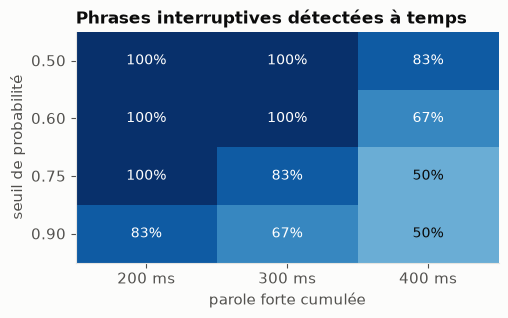

In [7]:
if len(bsweep):
    d = bsweep[bsweep.kind == "detect"].copy()
    d["ok"] = d.detect_ms.notna() & (d.detect_ms <= TH["detect_max_ms"])
    rate = d.groupby(["strict_prob", "min_ms"]).ok.mean().unstack()
    p50 = d.groupby(["strict_prob", "min_ms"]).detect_ms.median().unstack()
    fa = bsweep[bsweep.kind == "false"].groupby(["strict_prob", "min_ms"]).false_per_min.max().unstack()
    for name, t, fmt in [("Détection ≤ seuil (part des essais)", rate, "{:.0%}"), ("Délai de détection médian (ms)", p50, "{:.0f}"), ("Faux déclenchements / min (pire cas des 3 bruits)", fa, "{:.1f}")]:
        display(Markdown(f"**{name}** — lignes : seuil de probabilité, colonnes : durée de parole forte (ms)"))
        display(t.style.format(fmt))
    fig, ax = plt.subplots(figsize=(5.2, 3.3))
    im = ax.imshow(rate.values, cmap="Blues", vmin=0, vmax=1, aspect="auto")
    ax.set_xticks(range(rate.shape[1]), [f"{c} ms" for c in rate.columns]); ax.set_yticks(range(rate.shape[0]), [f"{r:.2f}" for r in rate.index])
    ax.set_xlabel("parole forte cumulée"); ax.set_ylabel("seuil de probabilité"); ax.set_title("Phrases interruptives détectées à temps")
    for i in range(rate.shape[0]):
        for j in range(rate.shape[1]):
            ax.text(j, i, f"{rate.values[i, j]:.0%}", ha="center", va="center", color="white" if rate.values[i, j] > .55 else INK, fontsize=10)
    ax.grid(False); fig.tight_layout(); fig.savefig(FIGS / "barge_threshold_sweep.png", dpi=150); plt.show()

## 4b. Écho : haut-parleur sans casque (simulation)

La voix de l'agent est réinjectée dans le micro avec un retard (`echo.delay_ms`) et un niveau relatif à la parole de référence (0 dB = écho aussi fort que l'utilisateur). Hors ligne, déterministe, sans réseau : `python scripts/run_campaign.py echosweep --out data/campaign/echo1 --stimuli data/campaign/run1`.

**Limites** : écho **synthétique et propre** (copie retardée de la voix, sans réverbération de pièce ni non-linéarité du haut-parleur), **sans l'annulation d'écho du navigateur** (`echoCancellation`), qui n'est pas simulée ; un écho réel résiduel est bruité, donc probablement moins bien reconnu comme parole par le VAD : ces chiffres sont un **cas pessimiste**. Le signal de l'agent est une voix de synthèse de la campagne (mêmes voix MiniMax, débit normal), pas la sortie réelle du serveur. Petits effectifs : intervalles de Wilson à 95 %.

In [8]:
ECHO = Path(os.environ["ECHO_RUN"]) if "ECHO_RUN" in os.environ else ROOT / "data" / "campaign" / "echo1"
es = pd.DataFrame(read_jsonl(ECHO / "echo_sweep.jsonl"))
eot = pd.DataFrame(read_jsonl(ECHO / "echo_eot.jsonl"))
ecfg = json.loads((ECHO / "meta.json").read_text())["config"]
E, EFIGS = ecfg["echo"], ECHO / "figs"; EFIGS.mkdir(exist_ok=True)
base_cfg = yaml.safe_load((ROOT / "configs" / "base.yaml").read_text())
CUR_SP, CUR_MM = base_cfg["session"]["barge_in_min_prob"], base_cfg["session"]["barge_in_min_speech_ms"]

def wilson(k, n, z=1.96):
    if n == 0: return (np.nan, np.nan)
    p = k / n; d = 1 + z * z / n
    c = (p + z * z / (2 * n)) / d; h = z * np.sqrt(p * (1 - p) / n + z * z / (4 * n * n)) / d
    return (max(0, c - h), min(1, c + h))

def fmt(k, n):
    lo, hi = wilson(k, n); return f"{k}/{n} ({k / n:.0%} ; {lo:.0%}–{hi:.0%})"

print(f"Écho simulé — retard {E['delay_ms']} ms — réglages du serveur : probabilité {CUR_SP}, parole forte {CUR_MM} ms")

Écho simulé — retard 150 ms — réglages du serveur : probabilité 0.6, parole forte 300 ms


**Faux barge-in** (l'agent parle, personne n'interrompt) aux réglages du serveur — un essai par signal d'agent et par gain

,faux barge-in
niveau de l'écho (dB / parole),
-60.0,0/11 (0% ; 0%–26%)
-50.0,7/11 (64% ; 35%–85%)
-40.0,10/11 (91% ; 62%–98%)
-30.0,11/11 (100% ; 74%–100%)
-20.0,11/11 (100% ; 74%–100%)
-10.0,11/11 (100% ; 74%–100%)
0.0,11/11 (100% ; 74%–100%)


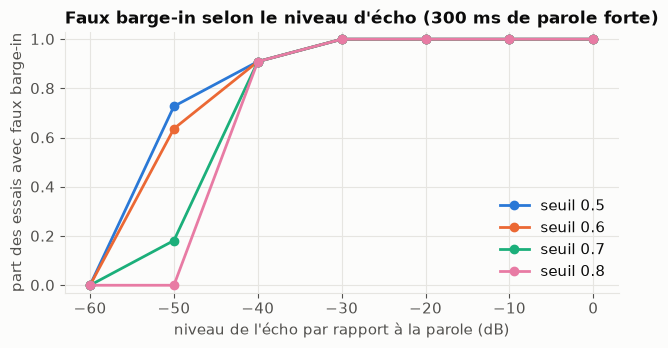

**Zone de transition (−50 dB)** — part de faux barge-in ; lignes : seuil de probabilité, colonnes : durée de parole forte (ms)

min_ms,200,300,400,500
strict_prob,,,,
0.500000,73%,73%,73%,73%
0.600000,73%,64%,64%,45%
0.700000,36%,18%,18%,18%
0.800000,0%,0%,0%,0%


In [9]:
f = es[es.kind == "false"]
cur = f[(f.strict_prob == CUR_SP) & (f.min_ms == CUR_MM)].groupby("gain_db").triggered.agg(["sum", "count"])
display(Markdown(f"**Faux barge-in** (l'agent parle, personne n'interrompt) aux réglages du serveur — un essai par signal d'agent et par gain"))
display(pd.DataFrame({"niveau de l'écho (dB / parole)": cur.index, "faux barge-in": [fmt(int(r["sum"]), int(r["count"])) for _, r in cur.iterrows()]}).set_index("niveau de l'écho (dB / parole)"))
fig, ax = plt.subplots(figsize=(6.4, 3.6))
for sp, color in zip(sorted(f.strict_prob.unique()), [BLUE, ORANGE, AQUA, MAGENTA]):
    r = f[(f.strict_prob == sp) & (f.min_ms == CUR_MM)].groupby("gain_db").triggered.mean()
    ax.plot(r.index, r.values, marker="o", color=color, label=f"seuil {sp}")
ax.set_xlabel("niveau de l'écho par rapport à la parole (dB)"); ax.set_ylabel("part des essais avec faux barge-in")
ax.set_title(f"Faux barge-in selon le niveau d'écho ({CUR_MM} ms de parole forte)"); ax.set_ylim(-.03, 1.03); ax.legend()
fig.tight_layout(); fig.savefig(EFIGS / "echo_false_barge.png", dpi=150); plt.show()
piv = f[f.gain_db == -50].groupby(["strict_prob", "min_ms"]).triggered.mean().unstack()
display(Markdown("**Zone de transition (−50 dB)** — part de faux barge-in ; lignes : seuil de probabilité, colonnes : durée de parole forte (ms)"))
display(piv.style.format("{:.0%}"))

In [10]:
d = es[es.kind == "detect"].copy(); d["gain_db"] = d.gain_db.fillna(99)
d["niveau d'écho"] = d.gain_db.map(lambda g: "sans écho" if g == 99 else f"{g:.0f} dB")
order = ["sans écho"] + [f"{g:.0f} dB" for g in sorted(E["gains_db"])]
cur = d[(d.strict_prob == CUR_SP) & (d.min_ms == CUR_MM)]
tab = pd.crosstab(cur["niveau d'écho"], cur.label).reindex(order).fillna(0).astype(int)
for c in ("ok", "false", "late", "missed"):
    if c not in tab: tab[c] = 0
display(Markdown("**Interruption de l'utilisateur par-dessus l'écho** aux réglages du serveur. `ok` = détectée à temps ; `false` = déclenchée *avant* la parole de l'utilisateur (par l'écho seul) ; `late` = trop tard ; `missed` = jamais"))
display(tab[["ok", "false", "late", "missed"]])
best = d.assign(ok=d.label == "ok").groupby(["strict_prob", "min_ms", "niveau d'écho"]).ok.mean().unstack()[order]
display(Markdown("**Part d'interruptions correctes selon les réglages** (lignes : seuil, durée ms ; colonnes : niveau d'écho)"))
display(best.style.format("{:.0%}"))

**Interruption de l'utilisateur par-dessus l'écho** aux réglages du serveur. `ok` = détectée à temps ; `false` = déclenchée *avant* la parole de l'utilisateur (par l'écho seul) ; `late` = trop tard ; `missed` = jamais

label,ok,false,late,missed
niveau d'écho,,,,
sans écho,32,0,0,0
-60 dB,31,0,1,0
-50 dB,32,0,0,0
-40 dB,8,24,0,0
-30 dB,4,28,0,0
-20 dB,0,32,0,0
-10 dB,0,32,0,0
0 dB,0,32,0,0


**Part d'interruptions correctes selon les réglages** (lignes : seuil, durée ms ; colonnes : niveau d'écho)

In [11]:
if len(eot):
    e2 = eot.copy(); e2["niveau d'écho"] = e2.gain_db.fillna(99).map(lambda g: "sans écho" if g == 99 else f"{g:.0f} dB")
    g = e2.groupby(["niveau d'écho", "end_silence_ms"]).agg(n=("cut", "size"), phrases_coupées=("cut", "mean"), délai_fin_médian_ms=("end_delay_ms", "median"))
    display(Markdown("**Fin de tour après une interruption réussie** (l'agent se tait `echo.agent_stop_ms` après la détection ; seules les interruptions détectées à temps sont comptées, donc n baisse quand l'écho monte)"))
    display(g.style.format({"phrases_coupées": "{:.0%}", "délai_fin_médian_ms": "{:.0f}"}))

**Fin de tour après une interruption réussie** (l'agent se tait `echo.agent_stop_ms` après la détection ; seules les interruptions détectées à temps sont comptées, donc n baisse quand l'écho monte)

## 4c. Fin de tour adaptative (étude hors ligne — non appliquée)

Question : peut-on garder un silence de fin de tour court tout en évitant de couper une phrase suspendue ? Idée : au silence court (`base`), regarder le texte du STT spéculatif ; s'il semble **incomplet** (dernier mot = déterminant, préposition, conjonction ; ponctuation suspendue ; énoncé très court — listes dans `adaptive:` de `campaign.yaml`), attendre jusqu'au silence long (`extended`). Pour une phrase complète, la décision tombe dès que le texte est prêt : le tour a de toute façon besoin du résultat du STT, donc **aucune latence ajoutée** [H, à vérifier en direct].

**Limites** : 12 énoncés synthétiques propres (n très petit) ; texte au moment de la pause **estimé** par répartition proportionnelle (pas de STT, pas d'alignement mot à mot) ; les phrases de test sont toutes bien terminées, donc le coût des fausses prolongations est sous-estimé ; la parole réelle hésite davantage.

In [12]:
rows = read_jsonl(ECHO / "eot_pauses.jsonl")
A = ecfg["adaptive"]
res = []
for S in A["base_silence_ms"]:
    for X in A["extended_silence_ms"]:
        cut_base = cut_ad = saved = extend_final = 0
        for r in rows:
            p0 = next((p for p in r["pauses"] if p["dur_ms"] >= S), None)
            base_cut = p0 is not None
            ad_cut = any((p["dur_ms"] >= S and not p["incomplete"]) or p["dur_ms"] >= X for p in r["pauses"])
            cut_base += base_cut; cut_ad += ad_cut; saved += base_cut and not ad_cut
            extend_final += r["final_incomplete"]
        res.append({"silence court (ms)": S, "silence long (ms)": X, "phrases coupées, fixe": fmt(cut_base, len(rows)),
                    "phrases coupées, adaptatif": fmt(cut_ad, len(rows)), "coupures évitées": saved,
                    "fins jugées incomplètes à tort": extend_final, "latence ajoutée si à tort (ms)": X - S})
display(pd.DataFrame(res).set_index(["silence court (ms)", "silence long (ms)"]))
display(Markdown("**Pauses internes détectées** (durée ≥ `min_pause_ms`) et verdict de l'heuristique sur le texte estimé"))
display(pd.DataFrame([{"énoncé": r["utt_id"], "pause (ms)": round(p["dur_ms"]), "texte estimé avant la pause": "…" + p["prefix"][-45:], "jugé incomplet": p["incomplete"]}
                      for r in rows for p in r["pauses"]]).set_index("énoncé"))

phrases coupées, fixe  \
silence court (ms) silence long (ms)                         
450                800                4/12 (33% ; 14%–61%)   
                   1000               4/12 (33% ; 14%–61%)   
600                800                 3/12 (25% ; 9%–53%)   
                   1000                3/12 (25% ; 9%–53%)   

                                     phrases coupées, adaptatif  \
silence court (ms) silence long (ms)                              
450                800                      3/12 (25% ; 9%–53%)   
                   1000                      1/12 (8% ; 1%–35%)   
600                800                      2/12 (17% ; 5%–45%)   
                   1000                      0/12 (0% ; 0%–24%)   

                                      coupures évitées  \
silence court (ms) silence long (ms)                     
450                800                               1   
                   1000                              3   
600                800                               1   
                   1000                              3   

                                      fins jugées incomplètes à tort  \
silence court (ms) silence long (ms)                                   
450                800                                             0   
                   1000                                            0   
600                800                                             0   
                   1000                                            0   

                                      latence ajoutée si à tort (ms)  
silence court (ms) silence long (ms)                                  
450                800                                           350  
                   1000                                          550  
600                800                                           200  
                   1000                                          400

**Pauses internes détectées** (durée ≥ `min_pause_ms`) et verdict de l'heuristique sur le texte estimé

,pause (ms),texte estimé avant la pause,jugé incomplet
énoncé,,,
u02,256,"…Merci,",True
u04,800,…un exposé demain sur les assistants vocaux et,True
u05,416,…Quelle est la différence entre un assistant,False
u06,480,…Explique-moi comment fonctionne,False
u06,256,"…nt fonctionne la reconnaissance de la parole,",True
u08,288,…prendre pourquoi la latence est si importante,False
u08,448,"…ence est si importante dans une conversation,",True
u09,352,…Si je coupe la parole,False
u09,320,…Si je coupe la parole à l'assistant en,True


## 5. Synthèse par rapport aux critères de réussite

In [13]:
out = []
if len(ok):
    out.append(("WER propre", f"{clean.mean():.1%}"))
    for noise in cfg["noise"]["types"]:
        worst = ok[ok.noise == noise].groupby("snr").wer.mean()
        out.append((f"WER {noise}, de {worst.index.max():.0f} dB à {worst.index.min():.0f} dB", " → ".join(f"{x:.0%}" for x in worst.sort_index(ascending=False))))
if len(lt):
    for cond, r in lt.iterrows():
        out.append((f"Latence {cond} : 1er son / début réponse (p50 · p95)",
                    (f"{r['1er son (mesuré) p50'] / 1000:.2f} s · {r['1er son (mesuré) p95'] / 1000:.2f} s / {r['début réponse (est.) p50'] / 1000:.2f} s · {r['début réponse (est.) p95'] / 1000:.2f} s (n={int(r['n'])}, échecs {int(r['échecs'])}/{int(r['tours testés'])})" if r["n"] else f"AUCUN tour abouti : {int(r['échecs'])} échecs sur {int(r['tours testés'])} testés ({int(r['ignorés'])} ignorés) — fin de parole jamais détectée")))
if len(B): out.append(("Interruptions correctement gérées", f"{int(B.ok.sum())}/{len(B)} = {B.ok.mean():.0%}"))
if len(fp) and "false_interrupts" in fp:
    out.append(("Faux barge-in (agent qui parle, bruit seul)", f"{int(fp[fp.valid].false_interrupts.sum())} sur {int(fp.valid.sum())} essais valides ({int((~fp.valid).sum())} invalides)"))
display(pd.DataFrame(out, columns=["critère", "résultat"]).set_index("critère"))
display(Markdown("""
**Limites** : parole et « foule » synthétiques (voix TTS, pas de vraie acoustique de pièce) ; **pas d'écho dans ces mesures** (casque supposé ; l'écho simulé est étudié séparément, sections 4b et 4c) ;
bruits blanc et foule seulement ; petits échantillons → p95 indicatif ; latence dépendante du réseau et des serveurs distants au moment de la mesure.
"""))

,résultat
critère,
WER propre,0.4%
"WER white, de 20 dB à 0 dB",0% → 0% → 2% → 16%
"WER babble, de 20 dB à 0 dB",0% → 0% → 4% → 67%
Latence clean_nofiller : 1er son / début réponse (p50 · p95),"2.09 s · 2.48 s / 2.06 s · 2.45 s (n=9, échecs..."
Latence clean_filler : 1er son / début réponse (p50 · p95),"0.52 s · 2.28 s / 2.10 s · 2.48 s (n=9, échecs..."
Latence white10_filler : 1er son / début réponse (p50 · p95),"0.58 s · 2.01 s / 2.25 s · 2.49 s (n=9, échecs..."
Latence babble20_filler : 1er son / début réponse (p50 · p95),"2.05 s · 2.05 s / 1.67 s · 1.67 s (n=1, échecs..."
Latence babble10_filler : 1er son / début réponse (p50 · p95),AUCUN tour abouti : 3 échecs sur 3 testés (7 i...
Interruptions correctement gérées,14/21 = 67%



**Limites** : parole et « foule » synthétiques (voix TTS, pas de vraie acoustique de pièce) ; **pas d'écho dans ces mesures** (casque supposé ; l'écho simulé est étudié séparément, sections 4b et 4c) ;
bruits blanc et foule seulement ; petits échantillons → p95 indicatif ; latence dépendante du réseau et des serveurs distants au moment de la mesure.
